# 01 · Exploratory data analysis
**Project:** Credit risk modelling and probability-of-default estimation with logistic regression
**Data:** UCI *Default of Credit Card Clients* (30,000 Taiwanese card holders, April–September 2005 behaviour, default observed in October 2005).

All numbers and charts below are produced by executing this notebook. Figures are written to `results/figures/`.
EDA uses the full dataset for description only; no modelling decisions are fitted here. Any preprocessing that learns from data (scaling, selection) is done later on the training split only.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd
from scipy import stats
from IPython.display import display
from src.data_loader import load_raw, sha256, DATA_DIR, XLS_NAME, TARGET
from src import visualisation as viz
viz.set_style()
df = load_raw()
print("shape:", df.shape)
print("source file sha256:", sha256(DATA_DIR / XLS_NAME)[:16], "...")

shape: (30000, 25)
source file sha256: 30c6be3abd8dcfd3 ...


## 1. Structure and data quality

In [2]:
print("dtypes:", df.dtypes.value_counts().to_dict())
print("missing values:", int(df.isna().sum().sum()))
print("fully duplicated rows:", int(df.duplicated().sum()))
print("duplicates ignoring ID:", int(df.drop(columns="ID").duplicated().sum()))
display(df.drop(columns="ID").describe().T.round(1))

dtypes: {dtype('int64'): 25}
missing values: 0
fully duplicated rows: 0
duplicates ignoring ID: 35


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
SEX,30000.0,1.6,0.5,1.0,1.0,2.0,2.0,2.0
EDUCATION,30000.0,1.9,0.8,0.0,1.0,2.0,2.0,6.0
MARRIAGE,30000.0,1.6,0.5,0.0,1.0,2.0,2.0,3.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
PAY_0,30000.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,30000.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_3,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_4,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_5,30000.0,-0.3,1.1,-2.0,-1.0,0.0,0.0,8.0


**Findings.** No missing values and no exact duplicates. 35 rows duplicate another record on every field except `ID`; with 23 mostly low-cardinality fields and many inactive accounts (zero balances, zero payments) this is plausible coincidence, so they are kept. `BILL_AMT` columns contain negative values (credit balances), and amounts are heavily right-skewed.

In [3]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    t = df.groupby(col)[TARGET].agg(n="size", default_rate="mean").round(3)
    print(col); display(t.T)
print("PAY_0 codes:", df["PAY_0"].value_counts().sort_index().to_dict())
print("PAY_2 code 1 count:", int((df["PAY_2"] == 1).sum()), "| PAY_0 code 1 count:", int((df["PAY_0"] == 1).sum()))

SEX


SEX,1,2
n,11888.000,18112.000
default_rate,0.242,0.208


EDUCATION


EDUCATION,0,1,2,3,4,5,6
n,14.0,10585.000,14030.000,4917.000,123.000,280.000,51.000
default_rate,0.0,0.192,0.237,0.252,0.057,0.064,0.157


MARRIAGE


MARRIAGE,0,1,2,3
n,54.000,13659.000,15964.000,323.00
default_rate,0.093,0.235,0.209,0.26


PAY_0 codes: {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}
PAY_2 code 1 count: 28 | PAY_0 code 1 count: 3688


**Findings.** `EDUCATION` codes 0, 5, 6 and `MARRIAGE` code 0 are undocumented. Their default rates are low and the groups are small (EDUCATION 0/4/5/6 together: 468 rows), so merging them into the documented "others" category is reasonable and will be stated explicitly in preprocessing. The `PAY_x` columns use -2 and 0, which the official description does not define, and `PAY_2`–`PAY_6` almost never take the value 1 whereas `PAY_0` does (3,688 rows). That is a coding irregularity in the source data, reported rather than repaired.

## 2. Target distribution

{0: 23364, 1: 6636} default rate = 0.2212


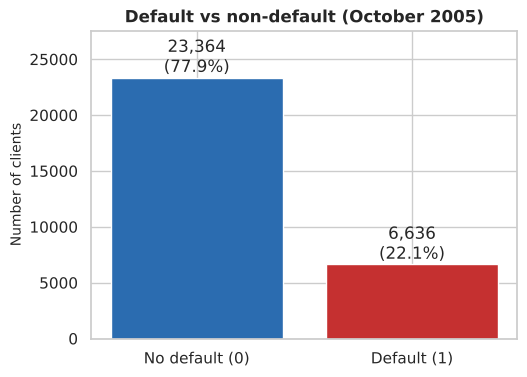

In [4]:
p = viz.plot_target(df)
print(df[TARGET].value_counts().to_dict(), f"default rate = {df[TARGET].mean():.4f}")

**Interpretation.** 22.1% of clients default, about 3.5 non-defaults per default. This is moderate imbalance: a model that predicts "no default" for everyone scores 77.9% accuracy while detecting no defaulters, so accuracy is not a sufficient metric. Evaluation will use PR-AUC, recall, KS and calibration, and stratified splitting.

## 3. Credit limit and age

{'count': 30000.0, 'mean': 167484.0, 'std': 129748.0, 'min': 10000.0, '25%': 50000.0, '50%': 140000.0, '75%': 240000.0, 'max': 1000000.0}
skewness: 0.99
age range: 21 - 79 | clients aged 65+: 110


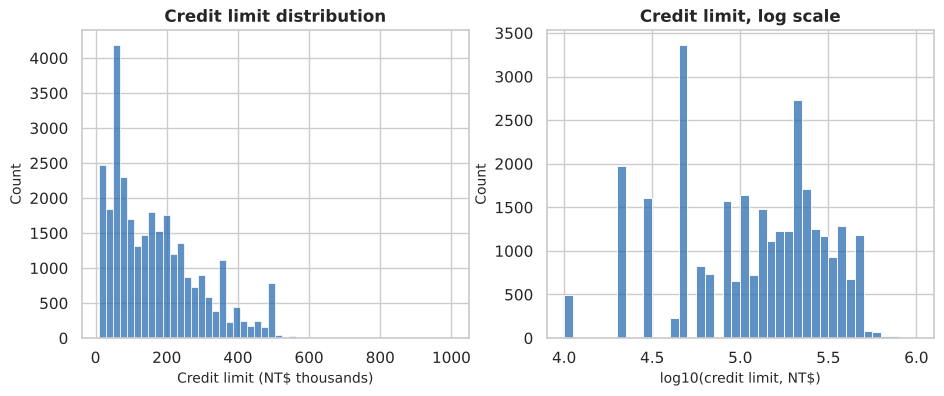

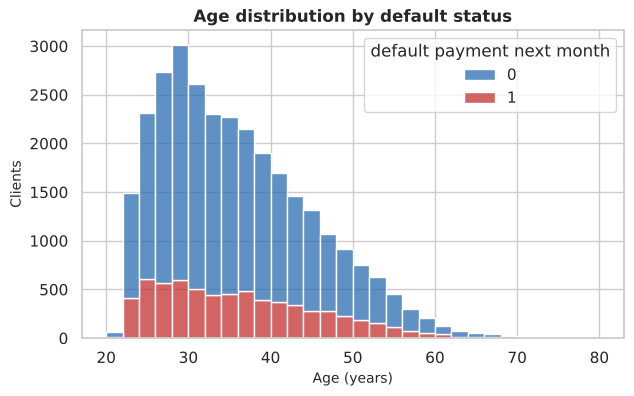

In [5]:
viz.plot_limit(df)
print(df["LIMIT_BAL"].describe().round(0).to_dict())
print("skewness:", round(stats.skew(df["LIMIT_BAL"]), 2))
viz.plot_age(df)
print("age range:", df["AGE"].min(), "-", df["AGE"].max(), "| clients aged 65+:", int((df["AGE"] >= 65).sum()))

**Interpretation.** Credit limits are right-skewed (skewness ≈ 1.0, median NT$140k, maximum NT$1M), so a log transform is a sensible candidate for the linear logit. Ages are concentrated between 25 and 45 (median 34); only 110 clients are 65 or older, so estimates for the oldest group are noisy.

## 4. Repayment status

share with PAY_0 in {-2,-1,0}: 0.773


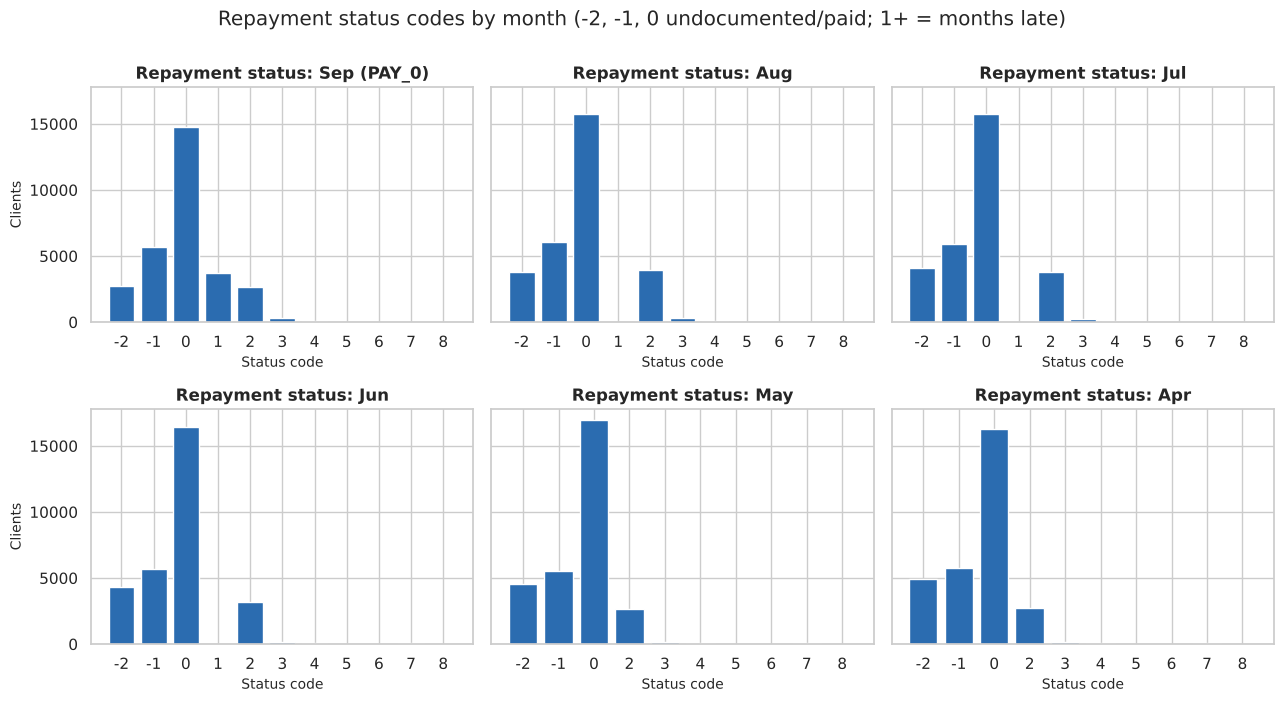

In [6]:
viz.plot_pay_status(df)
print("share with PAY_0 in {-2,-1,0}:", round(df["PAY_0"].isin([-2, -1, 0]).mean(), 3))

**Interpretation.** In every month roughly three quarters or more of clients are in codes -2, -1 or 0 (no delay or revolving). Late payers (codes 2 and above) are a minority, yet, as shown below, they carry most of the default risk.

## 5. Default rates across borrower characteristics

age_group,21-25,26-30,31-35,36-40,41-45,46-50,51-60,61+
mean,0.267,0.201,0.194,0.216,0.221,0.25,0.252,0.268
size,3871.000,7142.000,5796.000,4917.000,3605.000,2400.00,1997.000,272.000


limit_quintile,10k-50k,50k-100k,100k-180k,180k-270k,270k-1000k
mean,0.318,0.258,0.199,0.169,0.138
size,7676.000,4822.000,6123.000,5421.000,5958.000


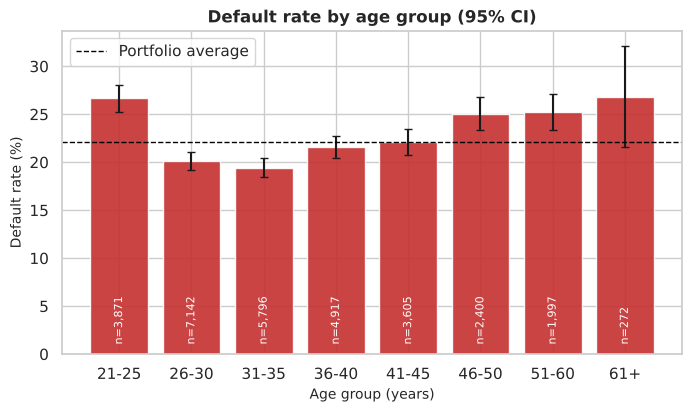

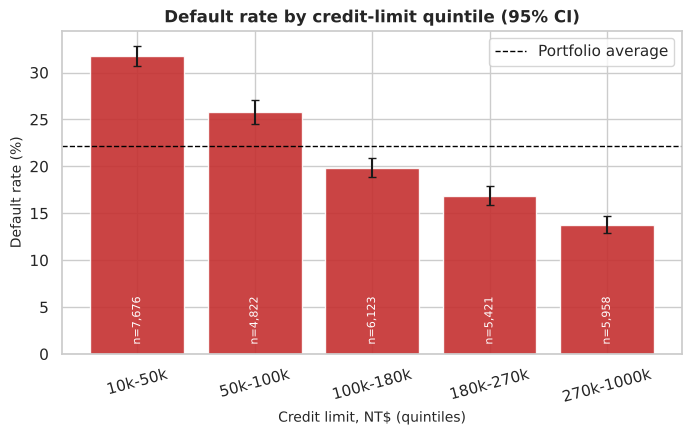

In [7]:
d = df.copy()
d["age_group"] = pd.cut(d["AGE"], [20, 25, 30, 35, 40, 45, 50, 60, 80],
                        labels=["21-25", "26-30", "31-35", "36-40", "41-45", "46-50", "51-60", "61+"])
_, g_age = viz.default_rate_plot(d, "age_group", "Default rate by age group (95% CI)", "Age group (years)",
                                 "06_default_rate_by_age_group.png")
display(g_age.round(3).T)
d["limit_quintile"] = pd.qcut(d["LIMIT_BAL"], 5)
d["limit_quintile"] = d["limit_quintile"].cat.rename_categories(
    lambda c: f"{c.left/1000:.0f}k-{c.right/1000:.0f}k")
_, g_lim = viz.default_rate_plot(d, "limit_quintile", "Default rate by credit-limit quintile (95% CI)",
                                 "Credit limit, NT$ (quintiles)", "07_default_rate_by_credit_limit.png", rot=15)
display(g_lim.round(3).T)

**Interpretation.**
- *Age:* the relationship is U-shaped. Default is highest in the youngest group (26.7% at 21–25), lowest around 26–35 (about 19–20%) and rises again after 45 (25–27%). A purely linear age term will therefore miss structure; an age-squared term or age bands are candidates.
- *Credit limit:* default falls monotonically with the limit, from 31.8% in the lowest quintile to 13.8% in the highest. Limits are set by the issuer using information we do not observe, so this partly reflects the issuer's own prior risk assessment.
- *Demographics:* men default more than women (24.2% vs 20.8%), and rates differ by education (university 23.7%, graduate 19.2%). These are associations, not causal effects, and SEX raises fair-lending concerns.

## 6. Repayment history versus default

PAY_0,-2,-1,0,1,2,3,4,5,6,7,8
n,2759.000,5686.000,14737.000,3688.000,2667.000,322.000,76.000,26.0,11.000,9.000,19.000
default_rate,0.132,0.168,0.128,0.339,0.691,0.758,0.684,0.5,0.545,0.778,0.579


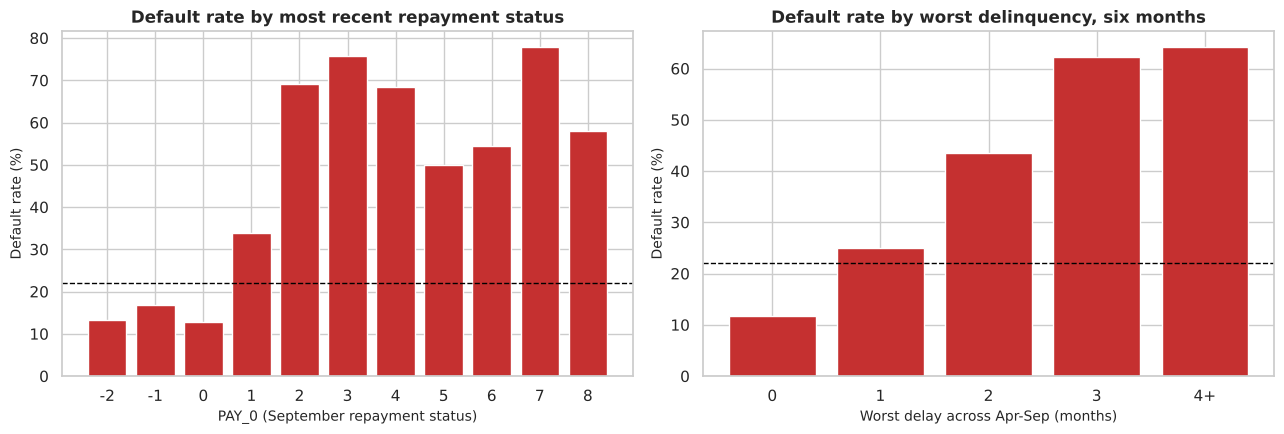

In [8]:
viz.plot_pay0_default(df)
display(df.groupby("PAY_0")[TARGET].agg(n="size", default_rate="mean").round(3).T)

**Interpretation.** Repayment status is by far the strongest signal. The default rate is 12.8% for status 0, 33.9% for a one-month delay and 69.1% for two months, then roughly 50–78% beyond (small samples). Status -2 and -1 (no balance or paid in full) sit at 13–17%, close to status 0, which supports treating -2/-1/0 as non-delinquent. The worst delay over six months shows the same monotone pattern.

## 7. Correlations, collinearity and outliers

,corr with default
PAY_0,0.325
PAY_2,0.264
PAY_3,0.235
PAY_4,0.217
PAY_5,0.204
PAY_6,0.187
LIMIT_BAL,-0.154
PAY_AMT1,-0.073


min pairwise correlation among the six BILL_AMT columns: 0.803
LIMIT_BAL IQR-rule outliers: 167
BILL_AMT1 IQR-rule outliers: 2400
PAY_AMT1 IQR-rule outliers: 2745
share with September bill above credit limit: 0.07


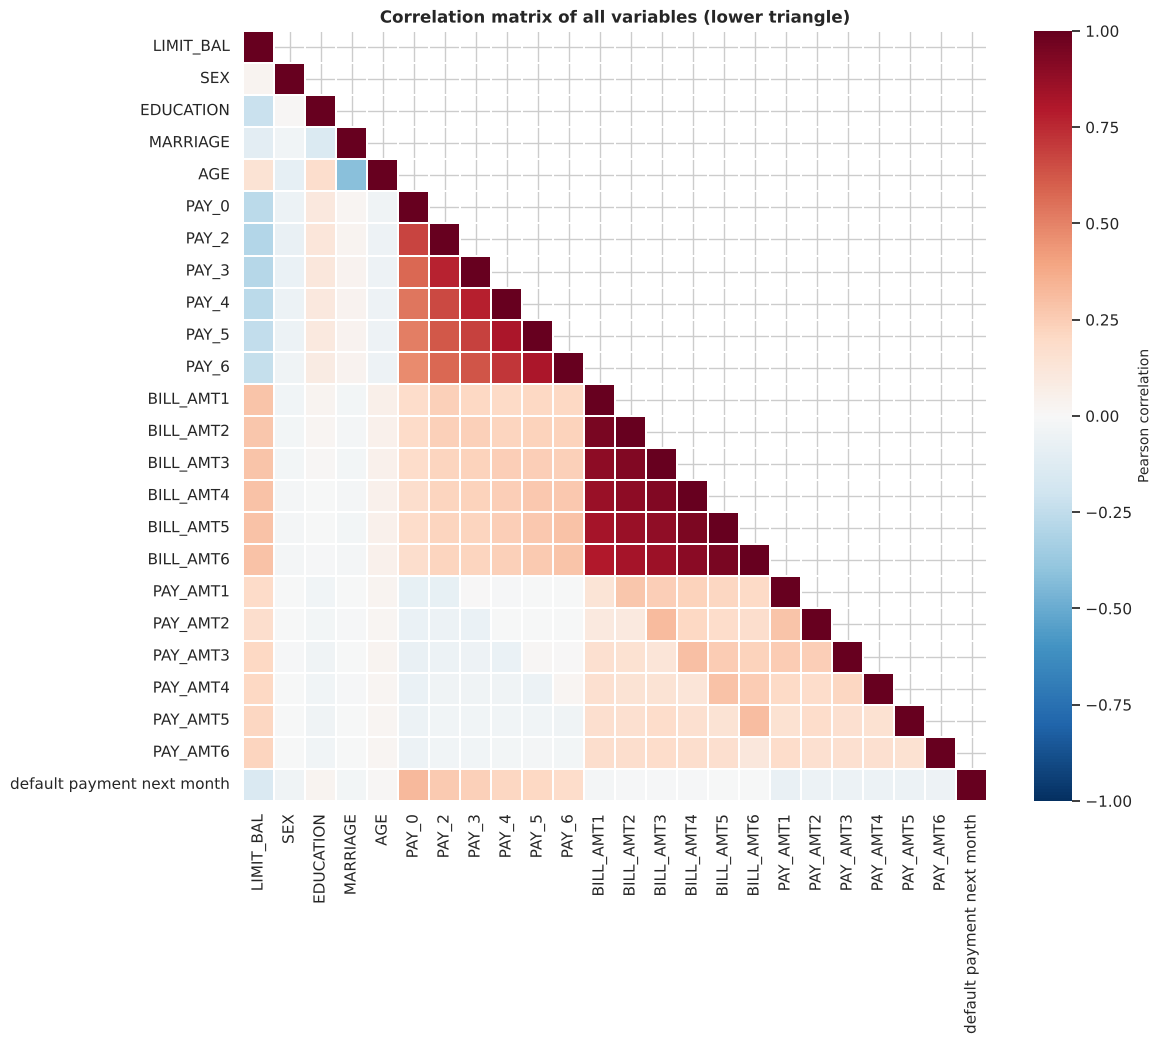

In [9]:
viz.plot_corr(df)
corr_t = df.drop(columns="ID").corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
display(corr_t.head(8).round(3).to_frame("corr with default"))
bill = [f"BILL_AMT{i}" for i in range(1, 7)]
print("min pairwise correlation among the six BILL_AMT columns:", df[bill].corr().values.min().round(3))
for c in ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    print(c, "IQR-rule outliers:", int(((df[c] > q3 + 1.5 * i) | (df[c] < q1 - 1.5 * i)).sum()))
print("share with September bill above credit limit:", round((df["BILL_AMT1"] > df["LIMIT_BAL"]).mean(), 3))

**Interpretation.**
- Correlations with the target are modest in linear terms: `PAY_0` (0.33), `PAY_2` (0.26) and `LIMIT_BAL` (−0.15) lead, and payment amounts are weakly negative.
- The six `BILL_AMT` columns are highly collinear (every pair ≥ 0.80), and the `PAY_x` columns are also correlated with each other. Unpenalised logistic coefficients will be unstable for these groups, which motivates L1/L2 regularisation and a VIF check in the coefficient analysis.
- Amount fields have thousands of IQR-rule outliers (about 2,400 for `BILL_AMT1`, 2,700 for `PAY_AMT1`), but these are large genuine balances and payments, not obvious errors. They will be handled by a transform (signed log) rather than deletion, and justified in the preprocessing notebook.

## 8. Summary of EDA findings carried into preprocessing
1. Target prevalence 22.1%: stratified splits; threshold and calibration analysis required.
2. Merge undocumented EDUCATION (0, 5, 6 with 4) and MARRIAGE (0 with 3) codes into "others"; document the choice.
3. Treat `PAY_x` as ordinal numeric, with an indicator-style delinquency feature as a candidate; do not recode -2/0.
4. Right-skewed amounts: signed-log transform, then standard scaling fitted on training data only.
5. Non-linear age effect: age squared or bands as a candidate.
6. Strong collinearity in `BILL_AMT` and `PAY_x`: regularisation, VIF diagnostics.
7. SEX excluded from the main model; reported as a sensitivity check.